Фильтр Калмана — это мощный инструмент, используемый для оценки состояния системы, особенно когда имеющиеся данные загрязнены шумом. В этом примере мы применяем фильтр Калмана для отслеживания положения и скорости объекта, который движется с ускорением.

Цель: Мы хотим точно оценить положение и скорость объекта, используя измерения, которые содержат шум. Фильтр Калмана помогает сгладить шум и дает наилучшую оценку текущего состояния объекта.

**Исходные данные**
Истинное состояние: Это реальные значения положения и скорости объекта, которые мы пытаемся оценить.
Измерения: Это наблюдаемые значения положения, которые содержат шум. Шум может быть вызван разными факторами, такими как погрешности датчиков.

**Фильтр Калмана**
Предсказание: Используя модель системы, фильтр предсказывает следующее состояние объекта.
Обновление: На основе новых измерений фильтр корректирует свои предсказания, чтобы они лучше соответствовали реальному состоянию объекта.

**Определение необходимых матриц и векторов**

В фильтре Калмана мы будем работать с несколькими ключевыми компонентами:

1. Состояние системы (вектор состояния): вектор, представляющий текущее состояние системы.
2. Вектор управления: вектор, представляющий внешние воздействия на систему.
3. Матрица перехода состояний: определяет, как текущее состояние переходит в следующее.
4. Матрица управления: определяет влияние вектора управления на состояние.
5. Матрица измерений: определяет, как состояние связано с измерениями.
6. Ковариация состояния: определяет неопределенность в состоянии.
7. Ковариация шума процесса: определяет неопределенность в процессе.
8. Ковариация шума измерений: определяет неопределенность в измерениях

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
class KalmanFilter:
    def __init__(self, initial_state, initial_covariance, state_transition_matrix,
                 control_matrix, measurement_matrix, process_noise_covariance,
                 measurement_noise_covariance):
        # Инициализация параметров фильтра
        self.state = initial_state  # Нынешнее состояние
        self.covariance = initial_covariance  # Ковариация состояния
        self.state_transition_matrix = state_transition_matrix  # Матрица перехода состояний
        self.control_matrix = control_matrix  # Матрица управления
        self.measurement_matrix = measurement_matrix  # Матрица измерений
        self.process_noise_covariance = process_noise_covariance  # Ковариация шума процесса
        self.measurement_noise_covariance = measurement_noise_covariance  # Ковариация шума измерений

    def predict(self, control_vector):
        # Предсказание следующего состояния
        self.state = self.state_transition_matrix @ self.state + self.control_matrix @ control_vector
        # Обновление ковариации с учетом шума процесса
        self.covariance = (self.state_transition_matrix @ self.covariance @
                           self.state_transition_matrix.T + self.process_noise_covariance)

    def update(self, measurement_vector):
        # Вычисление новизны (разницы между измерением и предсказанным состоянием)
        innovation = measurement_vector - (self.measurement_matrix @ self.state)
        # Ковариация новизны
        innovation_covariance = (self.measurement_matrix @ self.covariance @
                                  self.measurement_matrix.T + self.measurement_noise_covariance)

        # Вычисление Калмановского коэффициента
        kalman_gain = self.covariance @ self.measurement_matrix.T @ np.linalg.inv(innovation_covariance)

        # Обновление состояния и ковариации
        self.state = self.state + kalman_gain @ innovation
        self.covariance = self.covariance - kalman_gain @ self.measurement_matrix @ self.covariance

        return self.state, self.covariance


**Реализация предсказаний**

**Реализация обновления**

**Пример использования фильтра Калмана**

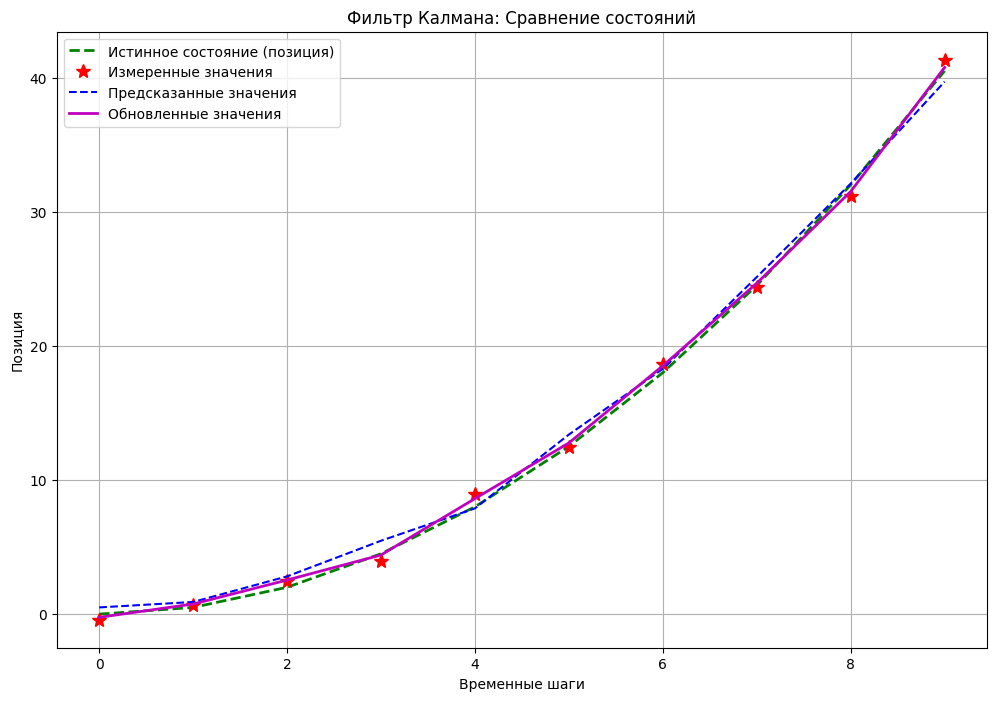

In [ ]:
# Пример использования фильтра Калмана с визуализацией
if __name__ == "__main__":
    # Начальные параметры
    initial_state = np.array([[0], [0]])  # Начальное состояние (позиция и скорость)
    initial_covariance = np.eye(2)  # Начальная ковариация
    state_transition_matrix = np.array([[1, 1], [0, 1]])  # Простая модель движения
    control_matrix = np.array([[0.5], [1]])  # Влияние управления
    measurement_matrix = np.array([[1, 0]])  # Измеряем только позицию
    process_noise_covariance = np.eye(2) * 0.1  # Ковариация шума процесса
    measurement_noise_covariance = np.eye(1) * 0.5  # Ковариация шума измерений

    # Создание объекта фильтра Калмана
    kf = KalmanFilter(initial_state, initial_covariance, state_transition_matrix,
                      control_matrix, measurement_matrix, process_noise_covariance,
                      measurement_noise_covariance)

    # Временные параметры
    num_iterations = 10
    true_states = []
    measurements = []
    predicted_states = []
    updated_states = []

    # Пример итераций предсказания и обновления
    for i in range(num_iterations):
        # Истинное состояние (позиция и скорость)
        true_position = 0.5 * i**2  # Пример: движение с ускорением
        true_velocity = i  # Пример: скорость
        true_states.append([true_position, true_velocity])

        control_input = np.array([[1]])  # Пример управления (ускорение)

        # Шум в измерениях
        measurement_noise = np.random.normal(0, 0.5)
        measurement_input = np.array([[true_position + measurement_noise]])  # Измеряем позицию с шумом
        measurements.append(measurement_input[0, 0])

        # Шаг предсказания
        kf.predict(control_input)
        predicted_states.append(kf.state[0, 0])

        # Шаг обновления
        current_state, confidence = kf.update(measurement_input)
        updated_states.append(current_state[0, 0])

    # Визуализация результатов
    plt.figure(figsize=(12, 8))
    time_steps = np.arange(num_iterations)
    true_states = np.array(true_states)

    plt.plot(time_steps, true_states[:, 0], 'g--', label='Истинное состояние (позиция)', linewidth=2)
    plt.plot(time_steps, measurements, 'r*', label='Измеренные значения', markersize=10)
    plt.plot(time_steps, predicted_states, 'b--', label='Предсказанные значения', linewidth=1.5)
    plt.plot(time_steps, updated_states, 'm-', label='Обновленные значения', linewidth=2)

    plt.title('Фильтр Калмана: Сравнение состояний')
    plt.xlabel('Временные шаги')
    plt.ylabel('Позиция')
    plt.legend()
    plt.grid()
    plt.show()